<a href="https://colab.research.google.com/github/Aakash109-hub/GeeksforGeeks-Python-Solutions/blob/main/Student_performance_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Understanding data through statistics and probability.

* Calculate mean, median, and mode.
* Understand variance and standard deviation.
* Understand percentiles and interquartile range (IQR).
* Understand basic probability and conditional probability.
* Calculate statistical measures using NumPy and Pandas.
* Interpret statistical results in a real-world scenario.

##Hands-on exercise: Student performance analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
data = {
    "student_id" : range(1,11),
    "score" : [55, 60, 65, 70, 70,
              75, 80, 85, 90, 100]
}
df = pd.DataFrame(data)
df

,student_id,score
0,1,55
1,2,60
2,3,65
3,4,70
4,5,70
5,6,75
6,7,80
7,8,85
8,9,90
9,10,100


In [8]:
#Calcualte Central Tendency
print("Mean :", df['score'].mean())
print("median :", df['score'].median())
print("Mode :", df['score'].mode().tolist())

Mean : 75.0
median : 72.5
Mode : [70]


In [15]:
#Calculatr Varience and Standard Deviation
scores = df['score'].to_numpy()

#population varience
print("varience:", np.var(scores))

#Population Standard Deviation
print("SD: ", np.std(scores))

#sample varience
print("Sample Var: ", np.var(scores, ddof= 1))

#sample Standard Deviation
print("Sample SD: ", np.std(scores, ddof = 1))

varience: 175.0
SD:  13.228756555322953
Sample Var:  194.44444444444446
Sample SD:  13.944333775567927


In [22]:
#Calcualte Percentile and IQR
q1 = df['score'].quantile(0.25)
q2 = df['score'].quantile(0.50)
q3 = df['score'].quantile(0.75)

iqr = q3-q1

print("Q1: ", q1)
print("Q2: ", q2)
print("Q3: ", q3)
print("IQR: ", iqr)

Q1:  66.25
Q2:  72.5
Q3:  83.75
IQR:  17.5


In [26]:
#Identify Potential Outliers

lower = q1 - 1.5*iqr

upper = q3 + 1.5*iqr

outliers = df[
    (df['score'] < lower) | (df['score'] > upper)
]
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Outliers: \n", outliers)

Lower Bound: 40.0
Upper Bound: 110.0
Outliers: 
 Empty DataFrame
Columns: [student_id, score]
Index: []


In [27]:
df['passed'] = df['score'] >= 70
df

,student_id,score,passed
0,1,55,False
1,2,60,False
2,3,65,False
3,4,70,True
4,5,70,True
5,6,75,True
6,7,80,True
7,8,85,True
8,9,90,True
9,10,100,True


In [29]:
#What is the probability that randomly selected student passed?
pass_prob = df['passed'].mean()
pass_prob

np.float64(0.7)

In [33]:
#What is the probability that randomly selected student scores at least 80?

atleast_80 = (df['score'] >= 80).mean()
prob_atleast_80 = atleast_80.mean()
prob_atleast_80

np.float64(0.4)

In [38]:
#what is the proababilty that a student scores atleast 80, given that the student passed?
count__80_plus = len(df[df['score']>=80])
count_pass = len(df[df['score']>=70])

prob_80_given_pass = count__80_plus/count_pass
prob_80_given_pass

0.5714285714285714

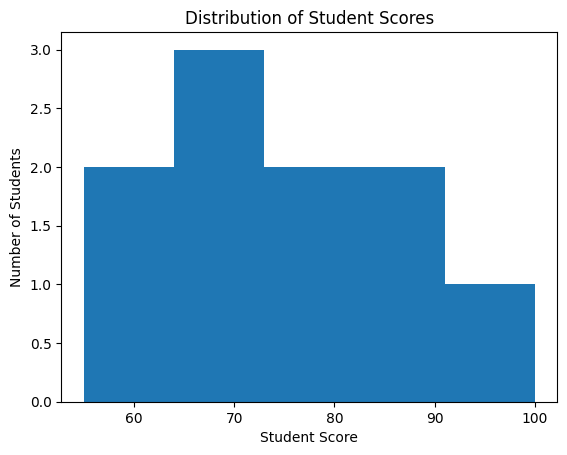

In [39]:
plt.hist(df["score"], bins=5)

plt.xlabel("Student Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Scores")

plt.show()


1. Mean vs median

Mean is the average of all values. Median is the middle value after sorting. Median is generally preferred when extreme values distort the mean.

2. Standard deviation

It measures how far values typically spread around the mean. A high standard deviation indicates greater variability.

3. Population vs sample variance

Population variance divides squared deviations by N. Sample variance divides them by N−1 to account for estimating population variability from a sample.

4. Outlier and IQR

An outlier is an observation unusually far from other observations. IQR detects potential outliers using Q1−1.5×IQR and Q3+1.5×IQR.

5. Probability vs conditional probability

Probability measures the likelihood of an event. Conditional probability measures the likelihood of an event when another event is already known to have occurred.

6. Mean or median?

Median is generally more reliable when extreme values are present because it is less affected by them.